# Australian Electricity Market (NEM) Analysis
### Prices, demand, renewables and battery value, a hands-on energy analyst project

**Author:** *your name* &nbsp;|&nbsp; **Tools:** Python, pandas, NumPy, Matplotlib, scikit-learn

---

## What this project does

This notebook walks through the analysis an energy analyst would do on **National Electricity Market (NEM)** data, from raw half-hourly records to business insights. It is written to be read top to bottom, with short explanations before every step.

**Dataset (included in `data/`):** two financial years (1 July 2024 to 30 June 2026) of half-hourly data for four NEM regions (**NSW1, QLD1, SA1, VIC1**), plus a daily gas price.

> **Important:** the data is **synthetic**. It was simulated (see `generate_data.py`) to behave like the real market: evening price peaks, midday negative prices, heatwave spikes, windy and calm periods, and gas-linked pricing. The numbers are realistic in scale but they are **not** real AEMO results. Do not quote them as facts about the market. The same code can be pointed at real AEMO price and demand files with minor column renaming.

## Questions we answer

1. How do average prices compare across regions and financial years?
2. How much of the average price comes from rare price spikes?
3. When are prices high and low during the day, and what is the "duck curve"?
4. How does temperature drive demand, and what happens during a heatwave?
5. How do wind and solar change prices (the *merit-order effect*)?
6. How strongly are electricity prices linked to the gas price?
7. How much could a grid battery earn from price arbitrage?
8. What would a simple cap contract (a hedge) be worth?
9. Can we forecast demand accurately with a simple machine-learning model?

## Skills demonstrated

Data cleaning and validation, time-series feature engineering, grouped aggregation, demand-weighted averages, risk and volatility metrics, regression and correlation, scenario modelling (batteries and hedging), machine-learning forecasting with a proper train/test split, and clear data visualisation.

## Key terms (quick glossary)

| Term | Meaning |
|---|---|
| **RRP** | Regional Reference Price, the wholesale spot price in A\$/MWh for a region |
| **Operational demand** | Demand met by grid-scale generation (rooftop solar already subtracted) |
| **VRE** | Variable renewable energy (wind + utility solar) |
| **Residual demand** | Demand left for coal, gas, hydro and batteries after wind and solar |
| **Merit order** | Generators dispatched cheapest first, so the last one needed sets the price |
| **Duck curve** | Midday demand dip (rooftop solar) followed by a steep evening ramp |
| **Market price cap / floor** | The maximum (about A\$17,500 in FY25 and A\$20,300 in FY26, approximate) and minimum (-A\$1,000) price allowed |

## Step 1. Setup

We import the libraries and set up one consistent chart style. Each region keeps **the same colour in every chart** so colours always mean the same thing. Charts use thin lines, quiet gridlines and a legend whenever there is more than one series.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 140)

# ---- Settings you can change ----
FOCUS_REGION = "SA1"          # region used for the deep-dive sections (try NSW1, QLD1 or VIC1)
REGIONS = ["NSW1", "QLD1", "SA1", "VIC1"]

# ---- Chart style: one fixed colour per region ----
REGION_COLORS = {"NSW1": "#2a78d6", "QLD1": "#eb6834", "SA1": "#1baf7a", "VIC1": "#eda100"}
FY_COLORS = {"FY25": "#86b6ef", "FY26": "#184f95"}          # light blue = earlier year, dark blue = later year
INK, INK_SOFT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "text.color": INK, "axes.labelcolor": INK_SOFT,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.8, "legend.frameon": False, "figure.dpi": 100,
})

def dollars(ax, axis="y"):
    # show axis ticks as $1,000 style
    fmt = mtick.FuncFormatter(lambda v, _: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

def legend_right(ax):
    # put the legend outside the plot so it never hides data
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))

HOUR_TICKS = list(range(0, 24, 3))
HOUR_LABELS = [f"{h:02d}:00" for h in HOUR_TICKS]
print("Setup complete. Focus region:", FOCUS_REGION)

Setup complete. Focus region: SA1


## Step 2. Load and explore the data

We load the two CSV files and look at their structure before doing anything else.

**Data dictionary: `nem_trading_30min.csv`**

| Column | Description | Unit |
|---|---|---|
| `settlement_date` | **End** of the 30-minute interval, in NEM time (AEST, no daylight saving) | timestamp |
| `region` | NEM region: NSW1, QLD1, SA1, VIC1 | text |
| `demand_mw` | Operational demand | MW |
| `wind_mw` | Wind generation | MW |
| `solar_mw` | Utility-scale solar generation | MW |
| `temperature_c` | Air temperature in the main city of the region | deg C |
| `rrp_aud_mwh` | Regional reference price (spot price) | A\$/MWh |

`gas_price_daily.csv` holds an illustrative east-coast wholesale gas price in A\$/GJ (`gas_price_aud_gj`).

In [2]:
df = pd.read_csv("data/nem_trading_30min.csv", parse_dates=["settlement_date"])
gas = pd.read_csv("data/gas_price_daily.csv", parse_dates=["date"])

print("Market data:", df.shape, "| Gas data:", gas.shape)
df.head()

Market data: (140166, 7) | Gas data: (730, 2)


,settlement_date,region,demand_mw,wind_mw,solar_mw,temperature_c,rrp_aud_mwh
0,2024-07-01 00:30:00,NSW1,"7,568.6",925.7,0.0,11.2,71.1
1,2024-07-01 00:30:00,QLD1,"6,367.4",547.0,0.0,13.5,64.5
2,2024-07-01 00:30:00,SA1,"1,450.6","1,094.1",0.0,7.8,68.9
3,2024-07-01 00:30:00,VIC1,"4,933.4","1,599.0",0.0,7.5,56.8
4,2024-07-01 01:00:00,NSW1,"7,699.6",754.8,0.0,10.3,80.8


In [3]:
# Quick statistical summary of the numeric columns
df.describe().T[["count", "mean", "min", "50%", "max"]]

,count,mean,min,50%,max
settlement_date,140166,2025-07-01 00:18:26.331064,2024-07-01 00:30:00,2025-07-01 00:30:00,2026-07-01 00:00:00
demand_mw,"140,166.0","5,250.0",283.1,"5,617.8","12,120.3"
wind_mw,"140,151.0",906.3,0.4,738.9,"4,014.7"
solar_mw,"140,166.0",535.3,0.0,0.2,"5,528.2"
temperature_c,"140,106.0",18.1,0.8,18.0,40.5
rrp_aud_mwh,"140,166.0",90.9,"-1,000.0",63.1,"20,300.0"


## Step 3. Check data quality and clean it

Real market data always has problems, so we check before analysing. Here we look for **missing values**, **duplicate rows**, the **expected number of rows** (730 days x 48 intervals x 4 regions) and **impossible values**.

> Some problems were added to this dataset on purpose so you can practise fixing them.

In [4]:
expected_rows = 730 * 48 * 4

print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0], "\n")
print("Duplicate region/time rows:", df.duplicated(subset=["settlement_date", "region"]).sum())
print(f"Rows: {len(df):,} (expected {expected_rows:,})")
print("Price range:", df["rrp_aud_mwh"].min(), "to", df["rrp_aud_mwh"].max())
print("Any negative demand?", (df["demand_mw"] < 0).any())

Missing values per column:
wind_mw          15
temperature_c    60
dtype: int64 



Duplicate region/time rows: 6
Rows: 140,166 (expected 140,160)
Price range: -1000.0 to 20300.0
Any negative demand? False


**Cleaning decisions**

- **Duplicates:** keep one row per region and time.
- **Short gaps** in temperature and wind (sensor dropouts): fill by linear interpolation within each region, limited to 4 consecutive intervals (2 hours). Longer gaps would need a different approach.
- **Prices are never filled in.** They are the most important variable, and there are no missing prices here.

In [5]:
# 1) remove duplicates and sort
df = (df.drop_duplicates(subset=["settlement_date", "region"])
        .sort_values(["region", "settlement_date"])
        .reset_index(drop=True))

# 2) fill short gaps inside each region
for col in ["temperature_c", "wind_mw"]:
    df[col] = df.groupby("region")[col].transform(lambda s: s.interpolate(limit=4))

# 3) confirm the data is now complete
assert len(df) == expected_rows, "unexpected number of rows"
assert df.isna().sum().sum() == 0, "missing values remain"
print(f"Clean dataset: {len(df):,} rows, no missing values.")

Clean dataset: 140,160 rows, no missing values.


## Step 4. Feature engineering (add useful columns)

Raw columns are rarely enough. We add time fields, financial-year labels, renewable share and flags for negative prices and spikes.

Two points that matter in practice:

- AEMO timestamps mark the **end** of an interval. A record stamped 18:00 covers 17:30 to 18:00, so we subtract 30 minutes to get the **interval start** before extracting the hour. Skipping this causes a one-interval error in every daily-pattern chart.
- Australian financial years run **1 July to 30 June**. FY25 is July 2024 to June 2025.

In [6]:
# time fields (based on interval START)
df["interval_start"] = df["settlement_date"] - pd.Timedelta(minutes=30)
df["date"] = df["interval_start"].dt.normalize()
df["hour"] = df["interval_start"].dt.hour
df["month"] = df["interval_start"].dt.month
df["is_weekend"] = df["interval_start"].dt.dayofweek >= 5
df["fy"] = np.where(df["interval_start"] < "2025-07-01", "FY25", "FY26")

SEASONS = {12: "Summer", 1: "Summer", 2: "Summer", 3: "Autumn", 4: "Autumn", 5: "Autumn",
           6: "Winter", 7: "Winter", 8: "Winter", 9: "Spring", 10: "Spring", 11: "Spring"}
df["season"] = df["month"].map(SEASONS)

# renewable and price features
df["vre_mw"] = df["wind_mw"] + df["solar_mw"]
df["vre_share"] = df["vre_mw"] / df["demand_mw"] * 100          # % of operational demand
df["residual_demand_mw"] = df["demand_mw"] - df["vre_mw"]
df["is_negative"] = df["rrp_aud_mwh"] < 0
df["is_spike"] = df["rrp_aud_mwh"] > 300                         # A$300/MWh is a common "high price" threshold
df["price_x_demand"] = df["rrp_aud_mwh"] * df["demand_mw"]       # used for demand-weighted prices

# add the daily gas price
df = df.merge(gas, on="date", how="left")

# month order for a financial year (July first)
MONTH_ORDER = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
MONTH_LABELS = ["Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun"]

df[["interval_start", "region", "fy", "season", "demand_mw", "vre_share", "rrp_aud_mwh", "gas_price_aud_gj"]].head()

,interval_start,region,fy,season,demand_mw,vre_share,rrp_aud_mwh,gas_price_aud_gj
0,2024-07-01 00:00:00,NSW1,FY25,Winter,"7,568.6",12.2,71.1,13.5
1,2024-07-01 00:30:00,NSW1,FY25,Winter,"7,699.6",9.8,80.8,13.5
2,2024-07-01 01:00:00,NSW1,FY25,Winter,"7,663.2",9.6,93.0,13.5
3,2024-07-01 01:30:00,NSW1,FY25,Winter,"7,729.8",9.4,93.1,13.5
4,2024-07-01 02:00:00,NSW1,FY25,Winter,"7,737.8",10.1,88.7,13.5


## Step 5. Market overview: how do regions and years compare?

For each region and financial year we calculate:

- **Average price:** the simple mean of all half-hourly prices.
- **Demand-weighted average price:** each price is weighted by demand. This is the price a typical **retailer** actually pays, because customers use more electricity when demand (and often price) is high.
- **Median price:** the "typical" interval. A median far below the mean is a sign of spikes.
- **Share of negative-price intervals** and **share above A\$300/MWh.**

In [7]:
g = df.groupby(["region", "fy"])

summary = g.agg(
    avg_price=("rrp_aud_mwh", "mean"),
    median_price=("rrp_aud_mwh", "median"),
    std_dev=("rrp_aud_mwh", "std"),
    pct_negative=("is_negative", "mean"),
    pct_above_300=("is_spike", "mean"),
    max_price=("rrp_aud_mwh", "max"),
)
summary["demand_weighted_price"] = g["price_x_demand"].sum() / g["demand_mw"].sum()
summary[["pct_negative", "pct_above_300"]] *= 100
summary = summary[["avg_price", "demand_weighted_price", "median_price", "std_dev",
                   "pct_negative", "pct_above_300", "max_price"]]
summary

avg_price  demand_weighted_price  median_price  std_dev  pct_negative  pct_above_300  max_price
region fy                                                                                                   
NSW1   FY25      111.1                  127.0          76.7    299.9          11.2            4.6   14,899.8
       FY26       83.2                   95.8          62.9    243.2          13.7            2.7   15,654.2
QLD1   FY25       96.9                  116.1          68.2    241.8          13.2            4.1   12,590.3
       FY26       77.6                   94.9          56.7    247.9          15.1            2.5   10,339.3
SA1    FY25      117.4                  137.7          77.1    407.4          13.8            4.4   17,500.0
       FY26       90.1                  106.8          64.1    315.0          14.6            2.7   20,300.0
VIC1   FY25       84.4                   95.4          59.4    233.6           9.8            2.7   11,726.7
       FY26       66.8                   76.4          47.6    211.3          12.4            1.9    7,505.7

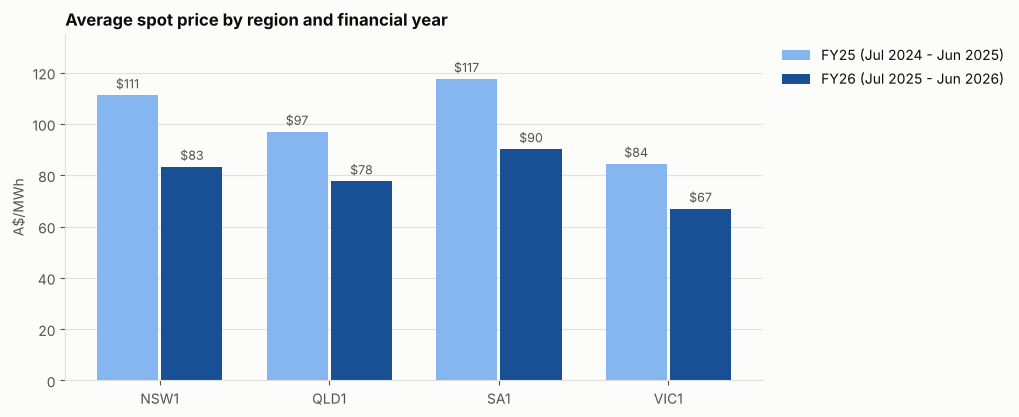

In [8]:
avg = summary["avg_price"].unstack("fy")          # rows = regions, columns = FY25 / FY26
x = np.arange(len(avg))

fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(x - 0.19, avg["FY25"], width=0.36, color=FY_COLORS["FY25"], label="FY25 (Jul 2024 - Jun 2025)")
b2 = ax.bar(x + 0.19, avg["FY26"], width=0.36, color=FY_COLORS["FY26"], label="FY26 (Jul 2025 - Jun 2026)")
ax.bar_label(b1, fmt="${:,.0f}", padding=3, color=INK_SOFT, fontsize=9)
ax.bar_label(b2, fmt="${:,.0f}", padding=3, color=INK_SOFT, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(avg.index)
ax.set_ylim(0, avg.values.max() * 1.15)
ax.set_title("Average spot price by region and financial year")
ax.set_ylabel("A$/MWh")
ax.grid(axis="x", visible=False)
legend_right(ax)
plt.show()

**What to notice:** the *mean* is well above the *median* in every region, so a small number of very high-priced intervals pulls the average up. Step 7 measures exactly how much.

## Step 6. Price trends over time

Monthly average prices show seasonality (winter and summer peaks) and how the market changed between the two years.

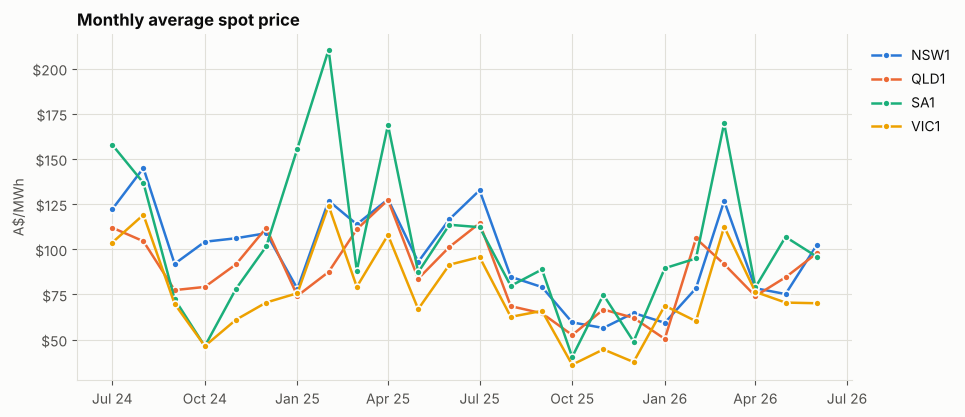

Highest-priced month in each region:


,month,avg_price
region,,
NSW1,Aug 2024,145.0
QLD1,Apr 2025,127.3
SA1,Feb 2025,210.5
VIC1,Feb 2025,124.2


In [9]:
monthly = (df.groupby([df["interval_start"].dt.to_period("M"), "region"])["rrp_aud_mwh"]
             .mean().unstack())
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4.5))
for r in REGIONS:
    ax.plot(monthly.index, monthly[r], color=REGION_COLORS[r], label=r,
            marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2)
ax.set_title("Monthly average spot price")
ax.set_ylabel("A$/MWh")
dollars(ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
legend_right(ax)
plt.show()

print("Highest-priced month in each region:")
pd.DataFrame({"month": monthly.idxmax().dt.strftime("%b %Y"), "avg_price": monthly.max()})

## Step 7. Volatility: price spikes and the price duration curve

Electricity prices are extremely **skewed**. Most intervals are cheap, but a few are extreme.

- The **price duration curve** sorts every interval from the most to the least expensive. It shows how often prices are high or negative.
- **Spike contribution** asks: *if we take the most expensive 1% (or 5%) of intervals, what share of the total price "value" do they account for?* This matters for generators (revenue depends on a few intervals), retailers (cost risk) and batteries (revenue is concentrated in spikes).

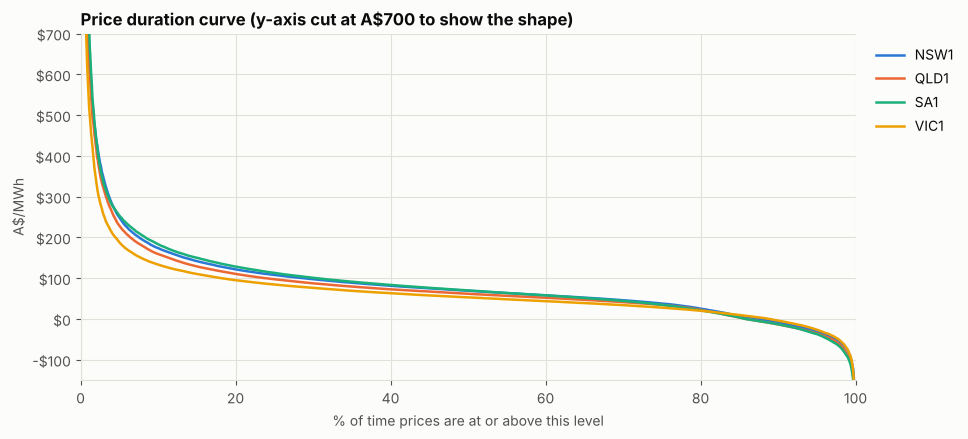

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for r in REGIONS:
    prices = np.sort(df.loc[df["region"] == r, "rrp_aud_mwh"].values)[::-1]    # high to low
    ax.plot(np.linspace(0, 100, len(prices)), prices, color=REGION_COLORS[r], label=r)
ax.set_ylim(-150, 700)
ax.set_xlim(0, 100)
ax.set_title("Price duration curve (y-axis cut at A$700 to show the shape)")
ax.set_xlabel("% of time prices are at or above this level")
ax.set_ylabel("A$/MWh")
dollars(ax)
legend_right(ax)
plt.show()

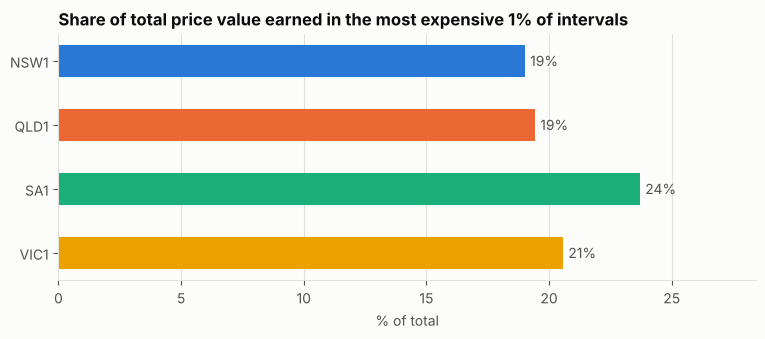

,top_1pct,top_5pct,top_10pct
region,,,
NSW1,19.0,34.5,45.0
QLD1,19.4,35.7,46.4
SA1,23.7,38.4,48.7
VIC1,20.6,35.8,46.1


In [11]:
rows = []
for r in REGIONS:
    p = df.loc[df["region"] == r, "rrp_aud_mwh"].sort_values(ascending=False)
    row = {"region": r}
    for pct in (1, 5, 10):
        k = int(len(p) * pct / 100)
        row[f"top_{pct}pct"] = p.iloc[:k].sum() / p.sum() * 100      # share of total price "value"
    rows.append(row)
spike_share = pd.DataFrame(rows).set_index("region")

fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.barh(spike_share.index, spike_share["top_1pct"], height=0.5,
               color=[REGION_COLORS[r] for r in spike_share.index])
ax.bar_label(bars, fmt="{:.0f}%", padding=4, color=INK_SOFT)
ax.invert_yaxis()
ax.set_xlim(0, spike_share["top_1pct"].max() * 1.2)
ax.set_title("Share of total price value earned in the most expensive 1% of intervals")
ax.set_xlabel("% of total")
ax.grid(axis="y", visible=False)
plt.show()

spike_share.round(1)

**What to notice:** about 1% of intervals (roughly 3.5 days a year) produce a large share of all price "value". This is why **price spikes dominate generator revenue and retailer risk**, and why averages alone can mislead.

## Step 8. Daily patterns: the evening peak, the duck curve and negative prices

We now look at how prices and demand behave through the day. We use the **interval start hour** created in Step 4.

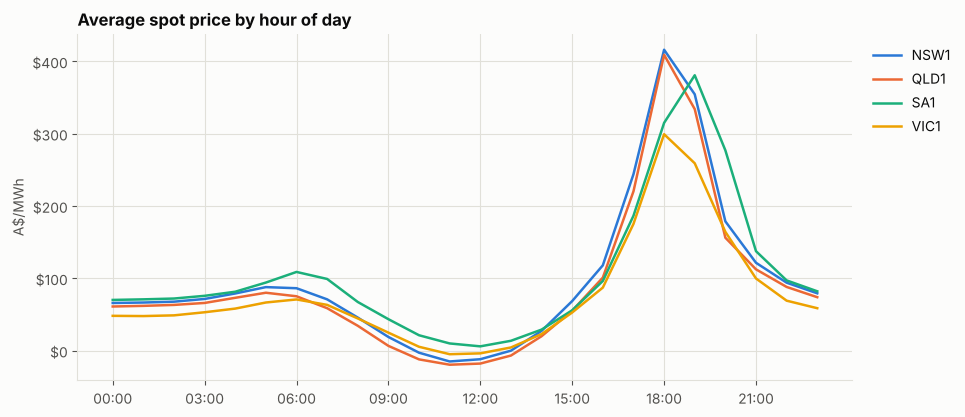

region,NSW1,QLD1,SA1,VIC1
hour,,,,
3,71.0,66.0,76.0,53.0
12,-12.0,-18.0,6.0,-4.0
18,416.0,409.0,315.0,299.0
19,355.0,334.0,381.0,259.0


In [12]:
hourly_price = df.groupby(["hour", "region"])["rrp_aud_mwh"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 4.5))
for r in REGIONS:
    ax.plot(hourly_price.index, hourly_price[r], color=REGION_COLORS[r], label=r)
ax.set_xticks(HOUR_TICKS)
ax.set_xticklabels(HOUR_LABELS)
ax.set_title("Average spot price by hour of day")
ax.set_ylabel("A$/MWh")
dollars(ax)
legend_right(ax)
plt.show()

hourly_price.loc[[3, 12, 18, 19]].round(0)

### The duck curve

Rooftop and utility solar push **midday demand from the grid down**, while the evening peak stays high because the sun has set. The gap between the two grows each year as more solar is installed. Below: average demand by hour for the focus region in **spring** (Sep to Nov), comparing the two years.

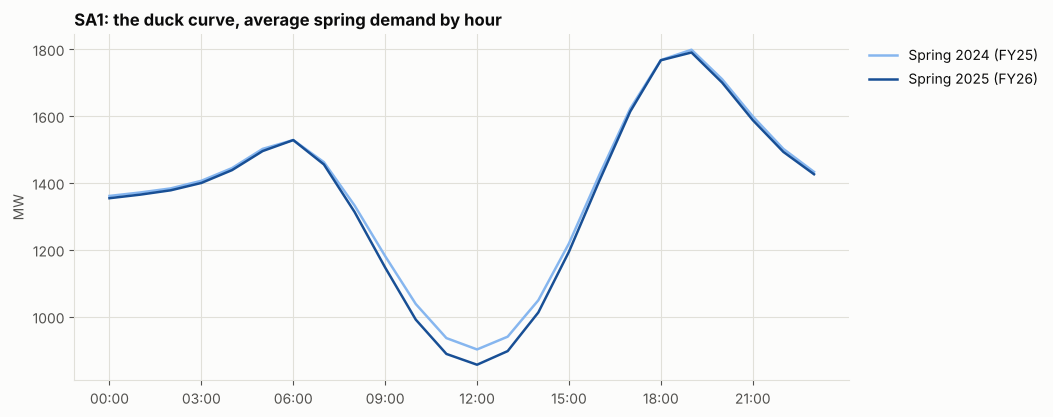

Lowest hourly average demand (MW):
fy
FY25   902.0
FY26   856.0


In [13]:
spring = df[(df["region"] == FOCUS_REGION) & (df["month"].isin([9, 10, 11]))]
duck = spring.groupby(["hour", "fy"])["demand_mw"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(duck.index, duck["FY25"], color=FY_COLORS["FY25"], label="Spring 2024 (FY25)")
ax.plot(duck.index, duck["FY26"], color=FY_COLORS["FY26"], label="Spring 2025 (FY26)")
ax.set_xticks(HOUR_TICKS)
ax.set_xticklabels(HOUR_LABELS)
ax.set_title(f"{FOCUS_REGION}: the duck curve, average spring demand by hour")
ax.set_ylabel("MW")
legend_right(ax)
plt.show()

print("Lowest hourly average demand (MW):")
print(duck.min().round(0).to_string())

### Negative prices

When solar and wind output exceeds demand, some generators will pay to keep running, so spot prices go **negative**. This is a distinctly Australian feature and is a major driver of battery and flexible-demand investment.

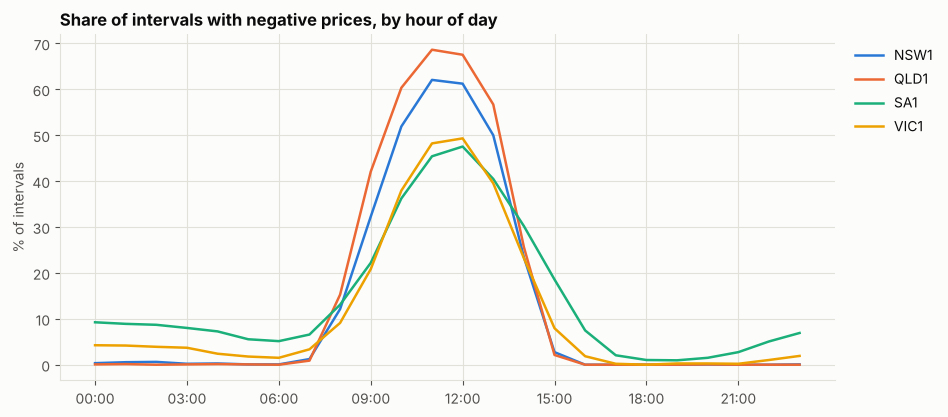

Share of ALL intervals with a negative price, by region and year (%):


fy,FY25,FY26
region,,
NSW1,11.2,13.7
QLD1,13.2,15.1
SA1,13.8,14.6
VIC1,9.8,12.4


In [14]:
neg_by_hour = df.groupby(["hour", "region"])["is_negative"].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
for r in REGIONS:
    ax.plot(neg_by_hour.index, neg_by_hour[r], color=REGION_COLORS[r], label=r)
ax.set_xticks(HOUR_TICKS)
ax.set_xticklabels(HOUR_LABELS)
ax.set_title("Share of intervals with negative prices, by hour of day")
ax.set_ylabel("% of intervals")
legend_right(ax)
plt.show()

print("Share of ALL intervals with a negative price, by region and year (%):")
summary["pct_negative"].unstack("fy").round(1)

## Step 9. Seasonality heatmaps (hour of day x month)

A heatmap shows two patterns at once: the **time of day** (vertical) and the **time of year** (horizontal). Darker means higher. Months run in financial-year order (July to June).

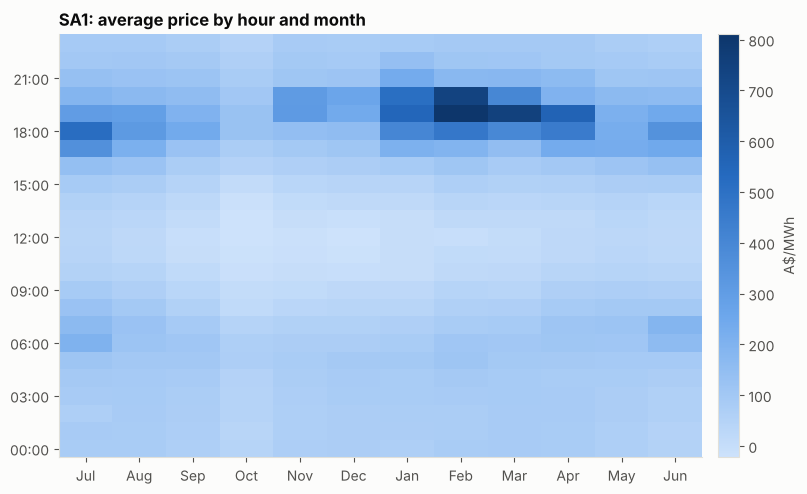

Most expensive hour/month combination: hour 19:00 in month 2 (average A$811/MWh)


In [15]:
def heatmap(data, title, cbar_label):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    im = ax.imshow(data.values, aspect="auto", cmap=BLUES, origin="lower")
    ax.set_xticks(range(12))
    ax.set_xticklabels(MONTH_LABELS)
    ax.set_yticks(HOUR_TICKS)
    ax.set_yticklabels(HOUR_LABELS)
    ax.grid(False)
    ax.set_title(title)
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(cbar_label)
    plt.show()

f = df[df["region"] == FOCUS_REGION]

price_heat = f.pivot_table(index="hour", columns="month", values="rrp_aud_mwh", aggfunc="mean")[MONTH_ORDER]
heatmap(price_heat, f"{FOCUS_REGION}: average price by hour and month", "A$/MWh")

hot_hour, hot_month = price_heat.stack().idxmax()
print(f"Most expensive hour/month combination: hour {hot_hour:02d}:00 in month {hot_month} "
      f"(average A${price_heat.stack().max():,.0f}/MWh)")

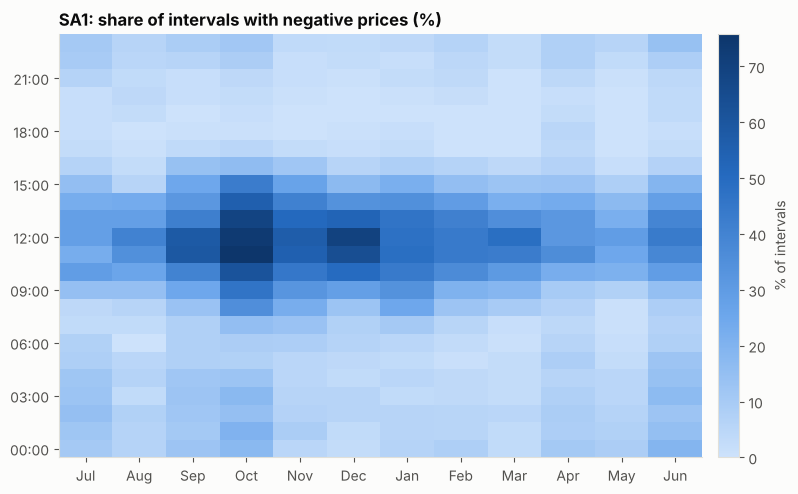

In [16]:
neg_heat = f.pivot_table(index="hour", columns="month", values="is_negative", aggfunc="mean")[MONTH_ORDER] * 100
heatmap(neg_heat, f"{FOCUS_REGION}: share of intervals with negative prices (%)", "% of intervals")

**What to notice:** high prices cluster in the **evening** (after the sun sets), especially in winter and summer. Negative prices cluster around **midday, especially in spring and early summer**, when solar is strong and demand is mild. Opposite problems at different times is why storage and flexible demand are valuable.

## Step 10. Demand and temperature

Heating and cooling drive demand, so the relationship between demand and temperature is **U-shaped**: demand rises when it is very cold and when it is very hot. To avoid mixing different times of day, we use **weekday evening peak intervals (5pm to 8pm)** for the focus region and group them into 2-degree temperature bins. The shaded band shows the 10th to 90th percentile range.

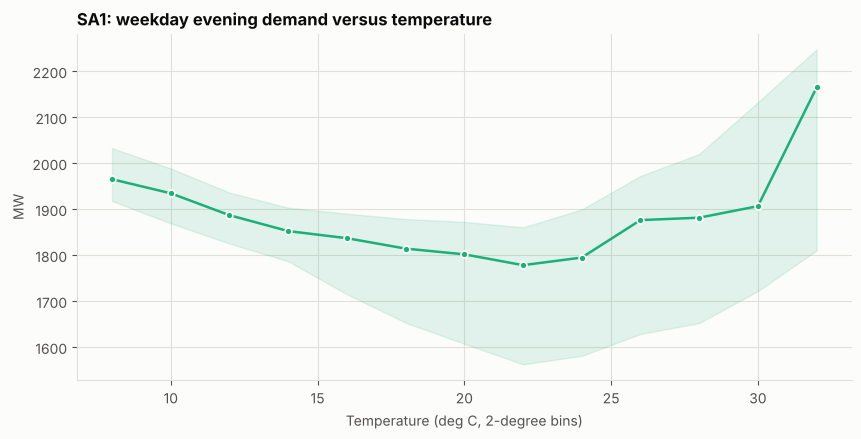

On hot evenings (above 28 deg C), demand rises by about 48 MW for each extra degree.


In [17]:
evening = f[f["hour"].between(17, 19) & ~f["is_weekend"]].copy()
evening["temp_bin"] = (evening["temperature_c"] // 2) * 2

curve = evening.groupby("temp_bin")["demand_mw"].agg(
    median="median", p10=lambda s: s.quantile(0.10), p90=lambda s: s.quantile(0.90), n="count")
curve = curve[curve["n"] >= 15]                      # ignore bins with very few observations

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(curve.index, curve["p10"], curve["p90"], color=REGION_COLORS[FOCUS_REGION], alpha=0.12)
ax.plot(curve.index, curve["median"], color=REGION_COLORS[FOCUS_REGION], marker="o",
        markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2)
ax.set_title(f"{FOCUS_REGION}: weekday evening demand versus temperature")
ax.set_xlabel("Temperature (deg C, 2-degree bins)")
ax.set_ylabel("MW")
plt.show()

# how much does demand rise per degree on hot days?
hot = evening[evening["temperature_c"] > 28]
cooling_slope = np.polyfit(hot["temperature_c"], hot["demand_mw"], 1)[0]
print(f"On hot evenings (above 28 deg C), demand rises by about {cooling_slope:,.0f} MW for each extra degree.")

### Peak demand case study

Peak demand sets how much generation and network capacity the system needs. Below are the five highest-demand intervals in the focus region, followed by a close look at three days around the **peak-demand interval** in the data (usually a heatwave).

In [18]:
f.nlargest(5, "demand_mw")[["interval_start", "demand_mw", "temperature_c", "wind_mw", "solar_mw", "rrp_aud_mwh"]]

,interval_start,demand_mw,temperature_c,wind_mw,solar_mw,rrp_aud_mwh
97191,2026-01-16 19:30:00,"2,346.7",36.2,"1,870.7",4.9,59.5
97189,2026-01-16 18:30:00,"2,343.9",37.7,"1,639.6",169.7,60.8
97190,2026-01-16 19:00:00,"2,332.3",36.2,"1,859.7",77.4,60.1
97142,2026-01-15 19:00:00,"2,325.3",36.5,"1,634.0",57.9,"3,703.3"
80916,2025-02-11 18:00:00,"2,316.9",36.1,880.8,148.5,178.1


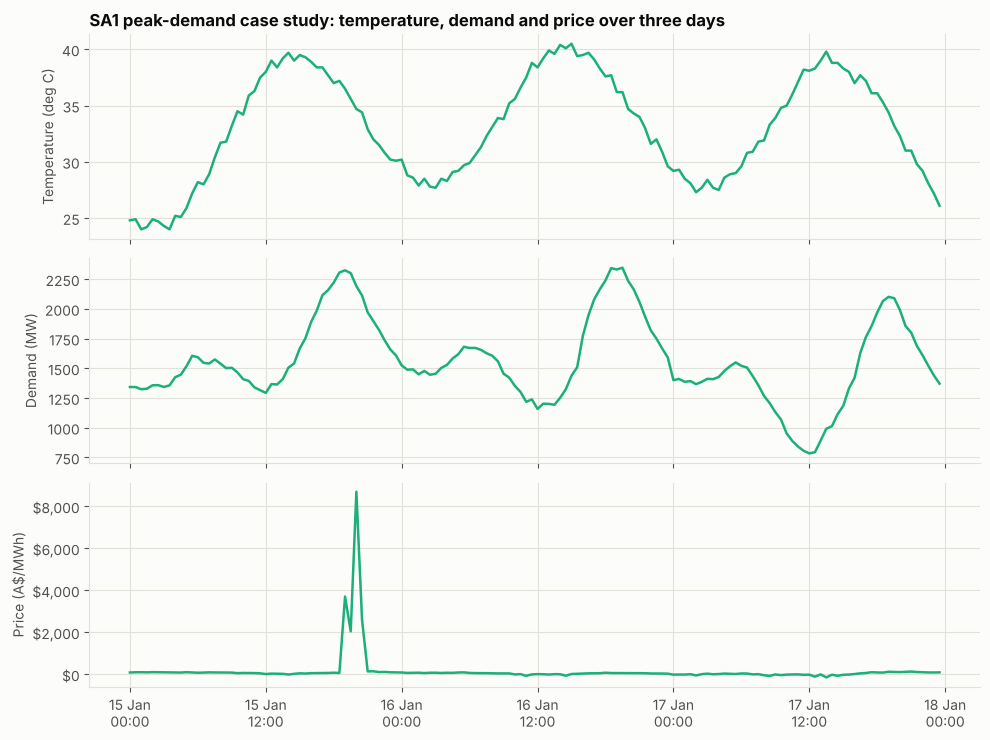

Peak-demand interval: 16 Jan 2026 19:30, 2,347 MW at 36.2 deg C
Highest price in this 3-day window: A$8,694/MWh
Average price in window: A$162/MWh vs A$104/MWh over the full two years


In [19]:
peak_row = f.loc[f["demand_mw"].idxmax()]
peak_ts = peak_row["interval_start"]
day = peak_ts.normalize()
window = f[(f["interval_start"] >= day - pd.Timedelta(days=1)) & (f["interval_start"] < day + pd.Timedelta(days=2))]

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
c = REGION_COLORS[FOCUS_REGION]
axes[0].plot(window["interval_start"], window["temperature_c"], color=c)
axes[0].set_ylabel("Temperature (deg C)")
axes[1].plot(window["interval_start"], window["demand_mw"], color=c)
axes[1].set_ylabel("Demand (MW)")
axes[2].plot(window["interval_start"], window["rrp_aud_mwh"], color=c)
axes[2].set_ylabel("Price (A$/MWh)")
dollars(axes[2])
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
axes[0].set_title(f"{FOCUS_REGION} peak-demand case study: temperature, demand and price over three days")
plt.tight_layout()
plt.show()

print(f"Peak-demand interval: {peak_ts:%d %b %Y %H:%M}, {peak_row['demand_mw']:,.0f} MW at {peak_row['temperature_c']:.1f} deg C")
print(f"Highest price in this 3-day window: A${window['rrp_aud_mwh'].max():,.0f}/MWh")
print(f"Average price in window: A${window['rrp_aud_mwh'].mean():,.0f}/MWh vs A${f['rrp_aud_mwh'].mean():,.0f}/MWh over the full two years")

**What to notice:** high demand does not automatically mean a price spike. What matters is **residual demand** (demand minus wind and solar). On a hot day with strong wind the market can stay calm, while a hot, calm evening can push prices to extreme levels. Step 11 looks at this directly.

## Step 11. Renewables and the merit-order effect

Wind and solar have almost **zero fuel cost**, so they are dispatched first and push expensive generators out of the market. The more renewable output there is, the **lower the price tends to be**. This is called the **merit-order effect**.

We measure it by grouping every interval by the **renewable share of demand** (wind + utility solar as a % of operational demand) and calculating the average price in each group. Groups with fewer than 100 intervals are hidden because their averages would be unreliable.

In [20]:
# average renewable share by region and year
vre_table = df.groupby(["region", "fy"])["vre_share"].mean().unstack()
vre_table["highest_share_seen"] = df.groupby("region")["vre_share"].max()
vre_table.round(1)

fy,FY25,FY26,highest_share_seen
region,,,
NSW1,17.7,20.8,99.4
QLD1,25.3,30.0,204.0
SA1,84.5,92.4,654.2
VIC1,32.8,36.8,170.6


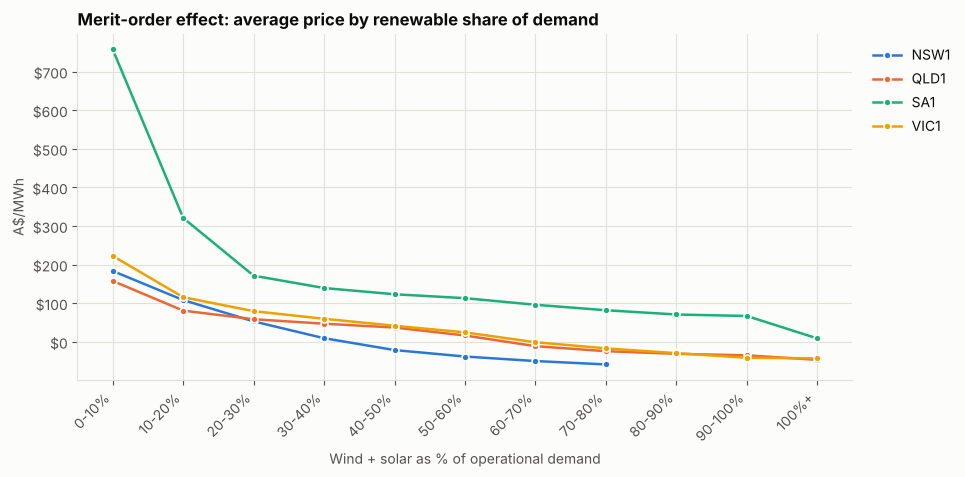

region,NSW1,QLD1,SA1,VIC1
vre_bucket,,,,
0-10%,184.0,158.0,758.0,223.0
10-20%,108.0,81.0,321.0,116.0
20-30%,53.0,59.0,171.0,79.0
30-40%,9.0,47.0,139.0,60.0
40-50%,-21.0,37.0,123.0,42.0
50-60%,-38.0,16.0,113.0,24.0
60-70%,-50.0,-11.0,96.0,-1.0
70-80%,-59.0,-24.0,82.0,-17.0
80-90%,NaN,-31.0,71.0,-29.0


In [21]:
bins = list(range(0, 101, 10)) + [np.inf]
labels = [f"{b}-{b + 10}%" for b in range(0, 100, 10)] + ["100%+"]
df["vre_bucket"] = pd.cut(df["vre_share"], bins=bins, labels=labels, include_lowest=True)

merit = df.groupby(["vre_bucket", "region"], observed=True)["rrp_aud_mwh"].agg(["mean", "count"]).reset_index()
avg_by_bucket = merit.pivot(index="vre_bucket", columns="region", values="mean")
n_by_bucket = merit.pivot(index="vre_bucket", columns="region", values="count")
avg_by_bucket = avg_by_bucket.where(n_by_bucket >= 100)

fig, ax = plt.subplots(figsize=(10, 4.5))
for r in REGIONS:
    ax.plot(range(len(avg_by_bucket)), avg_by_bucket[r].values, color=REGION_COLORS[r], label=r,
            marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.2)
ax.set_xticks(range(len(avg_by_bucket)))
ax.set_xticklabels(avg_by_bucket.index, rotation=45, ha="right")
ax.set_title("Merit-order effect: average price by renewable share of demand")
ax.set_xlabel("Wind + solar as % of operational demand")
ax.set_ylabel("A$/MWh")
dollars(ax)
legend_right(ax)
plt.show()

avg_by_bucket.round(0)

### When the wind drops: evening price risk

Solar disappears in the evening, so **wind output at the evening peak** becomes critical. We split evening intervals (5pm to 9pm) of the focus region into three equal groups by wind output and compare prices.

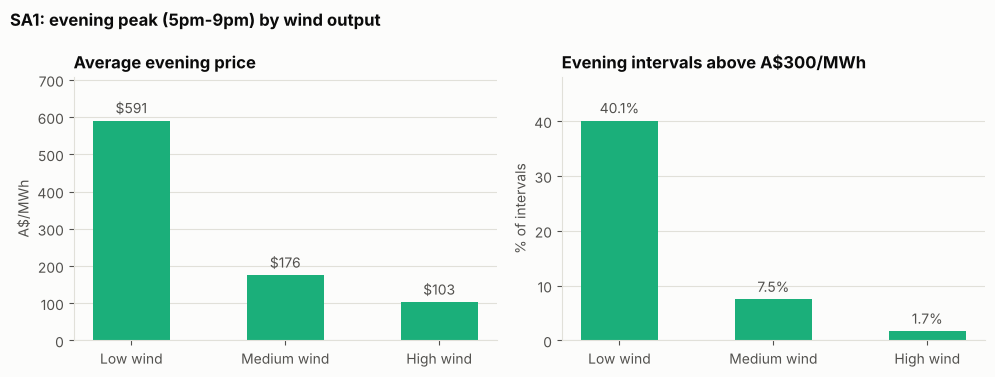

,avg_price,pct_above_300
wind_level,,
Low wind,590.5,40.1
Medium wind,175.6,7.5
High wind,103.0,1.7


In [22]:
ev = f[f["hour"].between(17, 20)].copy()
ev["wind_level"] = pd.qcut(ev["wind_mw"], 3, labels=["Low wind", "Medium wind", "High wind"])

lull = ev.groupby("wind_level", observed=True).agg(
    avg_price=("rrp_aud_mwh", "mean"), pct_above_300=("is_spike", "mean"))
lull["pct_above_300"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
c = REGION_COLORS[FOCUS_REGION]
b = axes[0].bar(lull.index, lull["avg_price"], width=0.5, color=c)
axes[0].bar_label(b, fmt="${:,.0f}", padding=3, color=INK_SOFT)
axes[0].set_ylim(0, lull["avg_price"].max() * 1.2)
axes[0].set_title("Average evening price")
axes[0].set_ylabel("A$/MWh")
axes[0].grid(axis="x", visible=False)
b = axes[1].bar(lull.index, lull["pct_above_300"], width=0.5, color=c)
axes[1].bar_label(b, fmt="{:.1f}%", padding=3, color=INK_SOFT)
axes[1].set_ylim(0, lull["pct_above_300"].max() * 1.2)
axes[1].set_title("Evening intervals above A$300/MWh")
axes[1].set_ylabel("% of intervals")
axes[1].grid(axis="x", visible=False)
fig.suptitle(f"{FOCUS_REGION}: evening peak (5pm-9pm) by wind output", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

lull.round(1)

## Step 12. How strongly are electricity prices linked to the gas price?

Gas-fired generators often set the price at the evening peak, so electricity prices tend to move with gas prices. Daily prices are very noisy (weather dominates), so we use **weekly averages** to see the underlying link. For each region we report:

- **Correlation:** how closely the two move together (from -1 to +1). We calculate it with all intervals, and again **excluding spike intervals** (above A\$300/MWh), which removes the extreme-weather noise.
- **Pass-through:** the slope of a straight-line fit, showing how many A\$/MWh the weekly average electricity price rises for each A\$1/GJ increase in gas. (As a rule of thumb, gas-fired generation needs about 8 to 10 GJ per MWh.)

In [23]:
weekly = (df.groupby(["region", pd.Grouper(key="date", freq="W")])
            .agg(avg_price=("rrp_aud_mwh", "mean"), gas=("gas_price_aud_gj", "mean")).reset_index())
weekly_ex = (df[~df["is_spike"]].groupby(["region", pd.Grouper(key="date", freq="W")])
               .agg(avg_price_ex_spikes=("rrp_aud_mwh", "mean")).reset_index())
weekly = weekly.merge(weekly_ex, on=["region", "date"])

rows = []
for r, d in weekly.groupby("region"):
    slope, intercept = np.polyfit(d["gas"], d["avg_price"], 1)
    rows.append({"region": r,
                 "corr_all_prices": d["avg_price"].corr(d["gas"]),
                 "corr_excl_spikes": d["avg_price_ex_spikes"].corr(d["gas"]),
                 "pass_through_per_GJ": slope})
gas_table = pd.DataFrame(rows).set_index("region")
gas_table.map(lambda v: f"{v:.2f}")

,corr_all_prices,corr_excl_spikes,pass_through_per_GJ
region,,,
NSW1,0.45,0.70,6.80
QLD1,0.38,0.70,4.65
SA1,0.06,0.21,1.45
VIC1,0.21,0.48,3.08


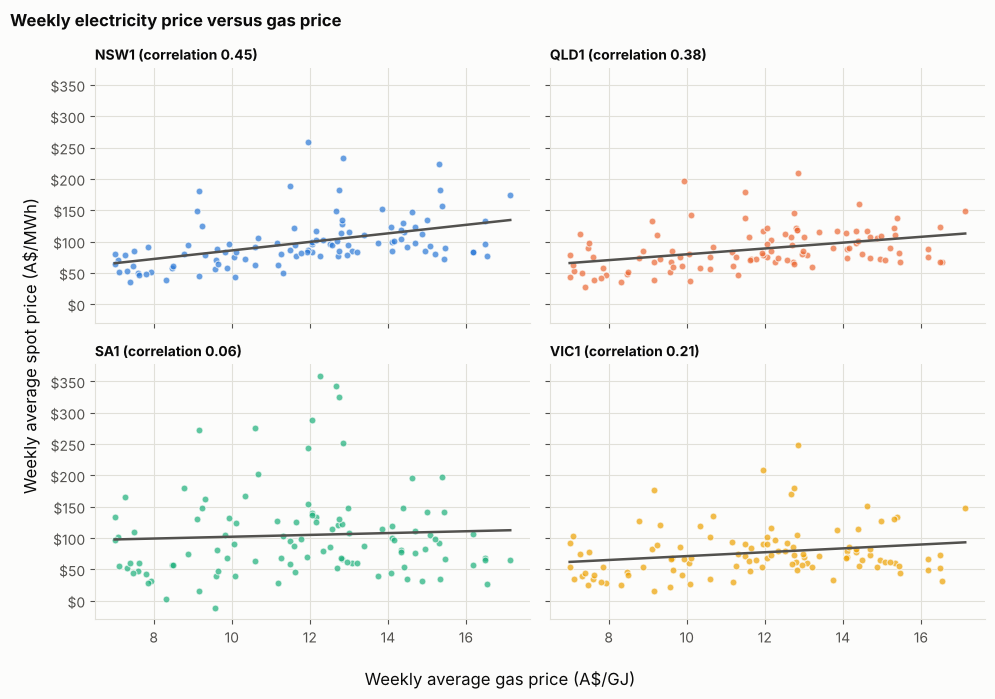

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, r in zip(axes.ravel(), REGIONS):
    d = weekly[weekly["region"] == r]
    slope, intercept = np.polyfit(d["gas"], d["avg_price"], 1)
    xs = np.array([d["gas"].min(), d["gas"].max()])
    ax.scatter(d["gas"], d["avg_price"], s=24, color=REGION_COLORS[r], alpha=0.7,
               edgecolors=SURFACE, linewidths=0.8)
    ax.plot(xs, intercept + slope * xs, color=INK_SOFT, linewidth=1.8)
    ax.set_title(f"{r} (correlation {d['avg_price'].corr(d['gas']):.2f})", fontsize=10)
    dollars(ax)
fig.supxlabel("Weekly average gas price (A$/GJ)")
fig.supylabel("Weekly average spot price (A$/MWh)")
fig.suptitle("Weekly electricity price versus gas price", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Caution:** this is correlation, not proof of cause. Weather affects both gas demand and electricity prices, and one big heatwave week can move the average a lot. Regions where wind and weather dominate show a weaker link. A more careful study would control for demand, wind and temperature.

## Step 13. How closely do the regions move together?

Regions are linked by **interconnectors**. When a link is not congested, neighbouring regions share one price; when it is full, prices **separate**. A correlation matrix of half-hourly prices and the frequency of large price differences give a quick view of regional integration. We focus on SA1 and VIC1, which are directly connected.

In [25]:
wide = df.pivot(index="interval_start", columns="region", values="rrp_aud_mwh")

print("Correlation of half-hourly prices between regions:")
display(wide.corr().map(lambda v: f"{v:.2f}"))

gap = (wide["SA1"] - wide["VIC1"]).abs()
sep = pd.DataFrame({
    "pct_time_gap_above_$50": [(gap[wide.index < "2025-07-01"] > 50).mean() * 100,
                               (gap[wide.index >= "2025-07-01"] > 50).mean() * 100],
    "avg_SA1_minus_VIC1": [(wide["SA1"] - wide["VIC1"])[wide.index < "2025-07-01"].mean(),
                           (wide["SA1"] - wide["VIC1"])[wide.index >= "2025-07-01"].mean()],
}, index=["FY25", "FY26"])
print("SA1 vs VIC1 price separation:")
sep.round(1)

Correlation of half-hourly prices between regions:


region,NSW1,QLD1,SA1,VIC1
region,,,,
NSW1,1.00,0.66,0.25,0.49
QLD1,0.66,1.00,0.17,0.32
SA1,0.25,0.17,1.00,0.48
VIC1,0.49,0.32,0.48,1.00


SA1 vs VIC1 price separation:


,pct_time_gap_above_$50,avg_SA1_minus_VIC1
FY25,29.0,33.1
FY26,22.9,23.3


## Step 14. Battery storage arbitrage (scenario model)

A grid battery earns money by **charging when prices are low and discharging when prices are high**. Here is a simple, transparent estimate of how much a **100 MW / 200 MWh** battery could earn from this alone.

**Assumptions (kept simple on purpose):**
- Each day the battery charges in the **4 cheapest** half-hours and discharges in the **4 most expensive** (4 x 0.5 h x 100 MW = 200 MWh).
- **85% round-trip efficiency.**
- It only trades on days when that is profitable.
- It knows the prices in advance (**perfect foresight**), so this is an **upper bound** and ignores the order of charge and discharge, degradation, network charges and ancillary (FCAS) revenue.

In [26]:
POWER_MW, DURATION_H, EFFICIENCY = 100, 2, 0.85
n_int = int(DURATION_H * 2)               # number of half-hours to charge and to discharge each day
mwh_per_interval = POWER_MW * 0.5         # 50 MWh moved per half-hour

def daily_battery_revenue(prices):
    p = np.sort(prices.values)
    charge_cost = p[:n_int].sum()                         # buy at the cheapest prices
    discharge_income = p[-n_int:].sum() * EFFICIENCY      # sell at the highest prices (after losses)
    return max(mwh_per_interval * (discharge_income - charge_cost), 0)

daily_rev = (df.groupby(["region", "date"])["rrp_aud_mwh"].apply(daily_battery_revenue)
               .rename("revenue").reset_index())
daily_rev["fy"] = np.where(daily_rev["date"] < "2025-07-01", "FY25", "FY26")

# revenue per MW of battery power per year, in A$ thousand
annual = daily_rev.groupby(["region", "fy"])["revenue"].sum().unstack() / POWER_MW / 1000
annual

fy,FY25,FY26
region,,
NSW1,328.3,255.2
QLD1,303.9,261.8
SA1,324.7,261.9
VIC1,232.2,213.9


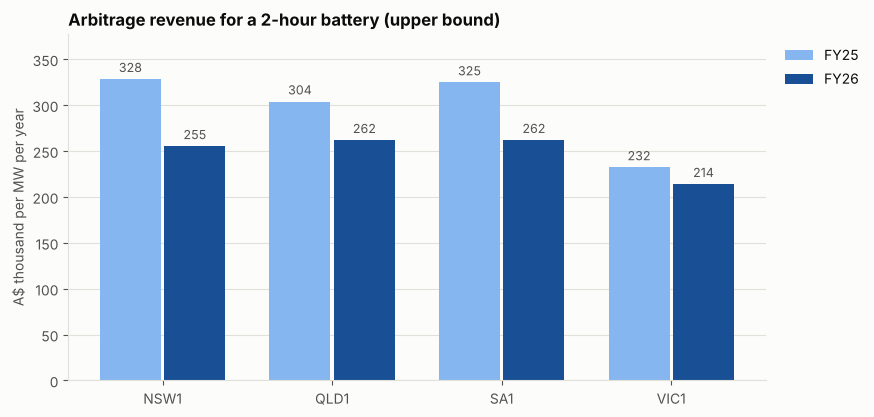

Share of two-year battery revenue earned on the best 10 days (out of 730):
region
NSW1    13%
QLD1    12%
SA1     19%
VIC1    14%


In [27]:
x = np.arange(len(annual))
fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(x - 0.19, annual["FY25"], width=0.36, color=FY_COLORS["FY25"], label="FY25")
b2 = ax.bar(x + 0.19, annual["FY26"], width=0.36, color=FY_COLORS["FY26"], label="FY26")
ax.bar_label(b1, fmt="{:,.0f}", padding=3, color=INK_SOFT, fontsize=9)
ax.bar_label(b2, fmt="{:,.0f}", padding=3, color=INK_SOFT, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(annual.index)
ax.set_ylim(0, annual.values.max() * 1.15)
ax.set_title("Arbitrage revenue for a 2-hour battery (upper bound)")
ax.set_ylabel("A$ thousand per MW per year")
ax.grid(axis="x", visible=False)
legend_right(ax)
plt.show()

top10 = daily_rev.groupby("region")["revenue"].apply(lambda s: s.nlargest(10).sum() / s.sum() * 100)
print("Share of two-year battery revenue earned on the best 10 days (out of 730):")
print(top10.round(0).astype(int).astype(str).add("%").to_string())

**What to notice:** a handful of extreme days produce a disproportionate share of the revenue (compare the best 10 days with the 730 days in the data). This is why battery business cases are sensitive to heatwaves, calm evenings and scarcity events, and why investors model **many price scenarios**, not just one average year.

## Step 15. A hedging view: what is a cap contract worth?

Retailers and large energy users **hedge** to protect themselves from price spikes. A **cap contract** with a A\$300/MWh strike pays the buyer the difference whenever the spot price rises above A\$300. Its fair value per MWh of hedged load is roughly the **average payout** over history.

In [28]:
STRIKE = 300
df["cap_payout"] = (df["rrp_aud_mwh"] - STRIKE).clip(lower=0)

hedge = df.groupby(["region", "fy"]).agg(avg_spot_price=("rrp_aud_mwh", "mean"),
                                        cap_value_per_mwh=("cap_payout", "mean"))
hedge["cap_value_as_pct_of_avg_price"] = hedge["cap_value_per_mwh"] / hedge["avg_spot_price"] * 100
hedge.round(1)

avg_spot_price  cap_value_per_mwh  cap_value_as_pct_of_avg_price
region fy                                                                    
NSW1   FY25           111.1               23.7                           21.3
       FY26            83.2               14.1                           17.0
QLD1   FY25            96.9               18.5                           19.1
       FY26            77.6               15.1                           19.4
SA1    FY25           117.4               30.3                           25.8
       FY26            90.1               20.1                           22.3
VIC1   FY25            84.4               14.8                           17.5
       FY26            66.8               13.1                           19.6

**What to notice:** the cap's value is a meaningful slice of the average price even though it only pays in a few percent of intervals. That gap between how *rarely* spikes happen and how *much* they matter is the heart of electricity risk management.

## Step 16. Forecasting demand with machine learning

Demand forecasting is a core task for retailers, network businesses and market operators. We forecast **half-hourly demand for the focus region** using calendar features and temperature.

**Method**
- **Train** on FY25 and **test** on FY26. We never test on data the model has seen, and we respect time order.
- **Baseline:** "same half-hour last week". Any useful model must beat this.
- **Model:** a Random Forest regressor (a robust, easy-to-use model that captures non-linear effects such as the U-shape in temperature).
- We use *actual* temperature, as if we had a perfect weather forecast. In real life, weather-forecast error adds to the demand-forecast error.

In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

m = df[df["region"] == FOCUS_REGION].sort_values("interval_start").reset_index(drop=True).copy()

# features
m["time_of_day"] = m["interval_start"].dt.hour * 2 + m["interval_start"].dt.minute // 30   # 0 to 47
m["day_of_week"] = m["interval_start"].dt.dayofweek
m["cooling_degrees"] = (m["temperature_c"] - 24).clip(lower=0)
m["heating_degrees"] = (15 - m["temperature_c"]).clip(lower=0)
m["demand_last_week"] = m["demand_mw"].shift(336)            # 336 half-hours = 7 days (the baseline)

FEATURES = ["time_of_day", "day_of_week", "month", "temperature_c", "cooling_degrees", "heating_degrees"]
train = m[m["fy"] == "FY25"]
test = m[m["fy"] == "FY26"].copy()

model = RandomForestRegressor(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=42)
model.fit(train[FEATURES], train["demand_mw"])
test["forecast_rf"] = model.predict(test[FEATURES])

def scores(actual, predicted):
    return {"MAE (MW)": mean_absolute_error(actual, predicted),
            "RMSE (MW)": mean_squared_error(actual, predicted) ** 0.5,
            "MAPE (%)": (abs(actual - predicted) / actual).mean() * 100}

results = pd.DataFrame({
    "Baseline: same time last week": scores(test["demand_mw"], test["demand_last_week"]),
    "Random Forest": scores(test["demand_mw"], test["forecast_rf"]),
}).T
results.round(2)

,MAE (MW),RMSE (MW),MAPE (%)
Baseline: same time last week,103.1,167.3,9.3
Random Forest,73.0,124.3,7.1


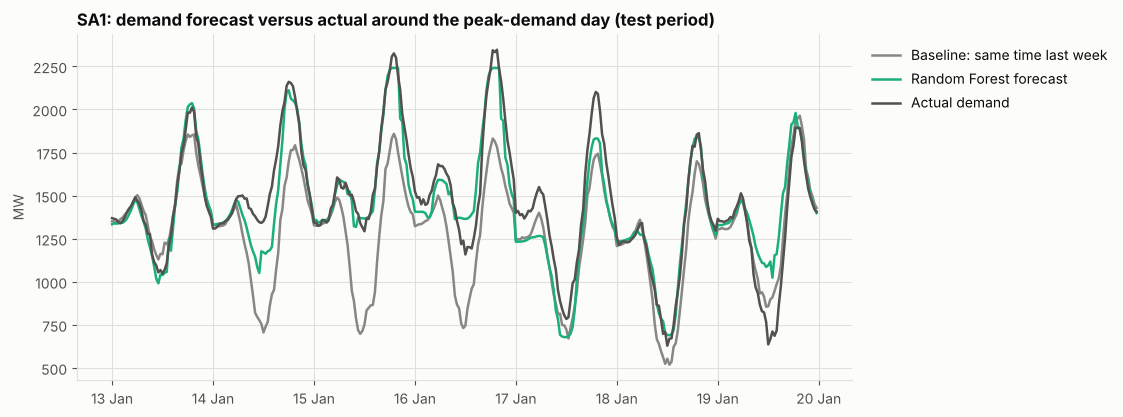

In [30]:
# Plot the week around the highest-demand interval in the test period
peak_time = test.loc[test["demand_mw"].idxmax(), "interval_start"].normalize()
wk = test[(test["interval_start"] >= peak_time - pd.Timedelta(days=3)) &
          (test["interval_start"] < peak_time + pd.Timedelta(days=4))]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(wk["interval_start"], wk["demand_last_week"], color=MUTED, label="Baseline: same time last week")
ax.plot(wk["interval_start"], wk["forecast_rf"], color=REGION_COLORS[FOCUS_REGION], label="Random Forest forecast")
ax.plot(wk["interval_start"], wk["demand_mw"], color=INK_SOFT, label="Actual demand")
ax.set_title(f"{FOCUS_REGION}: demand forecast versus actual around the peak-demand day (test period)")
ax.set_ylabel("MW")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
legend_right(ax)
plt.show()

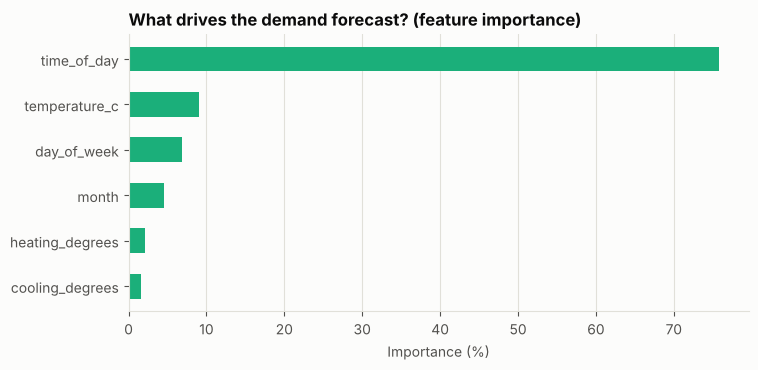

In [31]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(importance.index, importance.values * 100, height=0.55, color=REGION_COLORS[FOCUS_REGION])
ax.set_title("What drives the demand forecast? (feature importance)")
ax.set_xlabel("Importance (%)")
ax.grid(axis="y", visible=False)
plt.show()

**Reading the results:** the model should beat the baseline, especially when the weather differs from last week and "same as last week" breaks down. Remaining error is mostly the effect of **rooftop solar growth** (the test year has more solar than the training year) and random noise. Ideas to improve it: add public holidays, lagged demand, cloud cover or solar irradiance, and use time-series cross-validation.

## Step 17. Key findings (calculated from the data above)

These sentences are generated from the results, so they stay correct if you change the focus region or re-run the notebook with new data.

In [32]:
avg_fy = summary["avg_price"].unstack("fy")
change = (avg_fy["FY26"] / avg_fy["FY25"] - 1) * 100

print("1. AVERAGE PRICES (A$/MWh, FY25 -> FY26)")
for r in REGIONS:
    print(f"   {r}: {avg_fy.loc[r, 'FY25']:.0f} -> {avg_fy.loc[r, 'FY26']:.0f} ({change[r]:+.0f}%)")
gas_fy = df.drop_duplicates("date").groupby("fy")["gas_price_aud_gj"].mean()
print(f"   (Average gas price: A${gas_fy['FY25']:.1f}/GJ in FY25 versus A${gas_fy['FY26']:.1f}/GJ in FY26, a likely contributor.)")

print(f"\n2. SPIKES: the most expensive 1% of intervals earn {spike_share['top_1pct'].min():.0f}% to "
      f"{spike_share['top_1pct'].max():.0f}% of total price value, depending on region.")

peak_hour = hourly_price[FOCUS_REGION].idxmax()
mid = hourly_price.loc[11:14, FOCUS_REGION].mean()
print(f"\n3. DAILY SHAPE ({FOCUS_REGION}): prices peak around {peak_hour:02d}:00 "
      f"(A${hourly_price.loc[peak_hour, FOCUS_REGION]:.0f}/MWh) versus A${mid:.0f}/MWh at midday.")

neg = summary["pct_negative"].unstack("fy")
print(f"\n4. NEGATIVE PRICES ({FOCUS_REGION}): {neg.loc[FOCUS_REGION, 'FY25']:.0f}% of intervals in FY25 "
      f"and {neg.loc[FOCUS_REGION, 'FY26']:.0f}% in FY26.")

print(f"\n5. TEMPERATURE: on hot evenings in {FOCUS_REGION}, each extra degree adds about {cooling_slope:,.0f} MW of demand.")

low, high = lull.loc["Low wind", "avg_price"], lull.loc["High wind", "avg_price"]
print(f"\n6. WIND LULLS ({FOCUS_REGION} evenings): average price is A${low:.0f}/MWh in low-wind periods "
      f"versus A${high:.0f}/MWh in high-wind periods.")

best = gas_table["corr_all_prices"].idxmax()
weak = gas_table["corr_all_prices"].idxmin()
print(f"\n7. GAS: weekly prices follow gas most closely in {best} (correlation {gas_table.loc[best, 'corr_all_prices']:.2f}, "
      f"about A${gas_table.loc[best, 'pass_through_per_GJ']:.0f}/MWh per A$1/GJ) and least in {weak} "
      f"(correlation {gas_table.loc[weak, 'corr_all_prices']:.2f}).")

print(f"\n8. BATTERY ({FOCUS_REGION}, upper bound): about A${annual.loc[FOCUS_REGION, 'FY25']:.0f}k/MW in FY25 and "
      f"A${annual.loc[FOCUS_REGION, 'FY26']:.0f}k/MW in FY26; the best 10 days give {top10[FOCUS_REGION]:.0f}% of two-year revenue.")

rf, base = results.loc["Random Forest"], results.loc["Baseline: same time last week"]
print(f"\n9. FORECASTING ({FOCUS_REGION}): Random Forest MAPE {rf['MAPE (%)']:.1f}% versus {base['MAPE (%)']:.1f}% for the baseline.")

1. AVERAGE PRICES (A$/MWh, FY25 -> FY26)
   NSW1: 111 -> 83 (-25%)
   QLD1: 97 -> 78 (-20%)
   SA1: 117 -> 90 (-23%)
   VIC1: 84 -> 67 (-21%)
   (Average gas price: A$13.5/GJ in FY25 versus A$10.1/GJ in FY26, a likely contributor.)

2. SPIKES: the most expensive 1% of intervals earn 19% to 24% of total price value, depending on region.

3. DAILY SHAPE (SA1): prices peak around 19:00 (A$381/MWh) versus A$15/MWh at midday.

4. NEGATIVE PRICES (SA1): 14% of intervals in FY25 and 15% in FY26.

5. TEMPERATURE: on hot evenings in SA1, each extra degree adds about 48 MW of demand.

6. WIND LULLS (SA1 evenings): average price is A$591/MWh in low-wind periods versus A$103/MWh in high-wind periods.

7. GAS: weekly prices follow gas most closely in NSW1 (correlation 0.45, about A$7/MWh per A$1/GJ) and least in SA1 (correlation 0.06).

8. BATTERY (SA1, upper bound): about A$325k/MW in FY25 and A$262k/MW in FY26; the best 10 days give 19% of two-year revenue.

9. FORECASTING (SA1): Random Forest MA

### What this means for different players

| Who | Takeaway from the analysis |
|---|---|
| **Retailers** | Spikes, not averages, drive risk. Hedge the tail (caps) and watch evening wind and heat forecasts. |
| **Generators** | Revenue is concentrated in scarcity intervals and in the evening. Midday output is increasingly low-value. |
| **Battery and flexible-demand developers** | Midday low and negative prices plus evening peaks create the spread, but value depends on a few extreme days. |
| **Large energy users** | Shifting load to midday and away from the evening peak lowers cost; consider caps or time-of-use contracts. |
| **Policy and network analysts** | Rising solar deepens the duck curve, so system flexibility, firm capacity and interconnection matter more every year. |

### Limitations

- The data is **synthetic** and simplified: no outages, interconnector limits, FCAS markets, bidding behaviour or public holidays.
- The battery model assumes perfect foresight and ignores network charges, degradation and the order of charging and discharging.
- Correlation results (such as gas pass-through) are not proof of cause.

### Next steps to extend this project

1. **Replace the synthetic data with real AEMO data** (price and demand files are published on the AEMO website) and compare the findings.
2. Move to **5-minute data**, and add **FCAS** prices and **interconnector flows**.
3. Add **public holidays** and **solar irradiance** to the demand model, and try **price forecasting**.
4. Build an interactive **Power BI or Streamlit dashboard** on top of the cleaned data.
5. Optimise battery dispatch with realistic constraints (a simple linear program).

---
*This project is for learning and portfolio purposes. It is not financial advice.*